# How the objects fall into the LLaVA patch grid

LLaVA-1.5 sees a 336 × 336 image as a **24 × 24 grid of 14 × 14-pixel patches**. This notebook overlays that grid on the rendered images of the single- and two-object datasets so you can see where each object lands.

- **White lines:** patch boundaries (every 14 px).
- **Colored outline:** the object mask (its silhouette, without shadow).
- **Cross:** the object's projected center, which is always on a patch corner.
- **Numbers:** the fraction of a patch covered by the object.

The images, masks and coverage arrays come from `output/CLEVR_SINGLE_OBJECT/generation/` and `output/CLEVR_DUAL_OBJECT/generation/` (made by `image_generation/render_single_object_dataset.py` and `render_two_object_dataset.py`). Run the notebook from the repository root.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path.cwd()
SINGLE = ROOT / 'output' / 'CLEVR_SINGLE_OBJECT' / 'generation'
DUAL = ROOT / 'output' / 'CLEVR_DUAL_OBJECT' / 'generation'


IMAGE_SIZE, PATCH = 336, 14
N_PATCHES = IMAGE_SIZE // PATCH  # 24

single_meta = json.loads((SINGLE / 'metadata.json').read_text())
single_cov = np.load(SINGLE / 'coverage.npz')
dual_scenes = json.loads((DUAL / 'scenes.json').read_text())
dual_cov = np.load(DUAL / 'coverage.npz')

print(f'{len(single_meta)} single-object images, {len(dual_scenes)} two-object images')

864 single-object images, 1296 two-object images


In [2]:
OUTLINE_COLORS = ['yellow', 'magenta']


def load_image(path):
    """RGB image as floats in [0, 1], top row first."""
    return plt.imread(path)[..., :3]


def draw_grid(ax, color='white', alpha=0.35, lw=0.5):
    for k in range(0, IMAGE_SIZE + 1, PATCH):
        ax.axhline(k - 0.5, color=color, alpha=alpha, lw=lw)
        ax.axvline(k - 0.5, color=color, alpha=alpha, lw=lw)


def show(ax, image, masks=(), centers=(), title=None, grid=True):
    """Image with patch grid, mask outlines and projected centers."""
    ax.imshow(image)
    if grid:
        draw_grid(ax)
    for mask, color in zip(masks, OUTLINE_COLORS):
        ax.contour(mask, levels=[0.5], colors=color, linewidths=0.8)
    for (x, y), color in zip(centers, OUTLINE_COLORS):
        # Pixel (i, j) covers [i, i+1); imshow puts its center at i, hence -0.5
        ax.plot(x - 0.5, y - 0.5, '+', color=color, ms=6, mew=1)
    ax.set_xlim(-0.5, IMAGE_SIZE - 0.5)
    ax.set_ylim(IMAGE_SIZE - 0.5, -0.5)
    ax.set_xticks([])
    ax.set_yticks([])
    if title:
        ax.set_title(title, fontsize=8)


def single_mask(shape, position):
    """Per-pixel and per-patch coverage of one shape at one position."""
    k = np.flatnonzero((single_cov['shapes'] == shape) &
                       (single_cov['position_index'] == position))[0]
    return single_cov['pixel_coverage'][k], single_cov['patch_coverage'][k]


def dual_mask(shape, position):
    k = np.flatnonzero((dual_cov['mask_shapes'] == shape) &
                       (dual_cov['mask_position_ids'] == position))[0]
    return dual_cov['mask_pixel_coverage'][k], dual_cov['mask_patch_coverage'][k]

## 1. Single object: one shape and color at all 36 positions

Change `SHAPE` and `COLOR` to look at other combinations. The title of each tile gives the position index, the number of patches the object touches, and the number of *fragment* patches (covered by less than 10%).

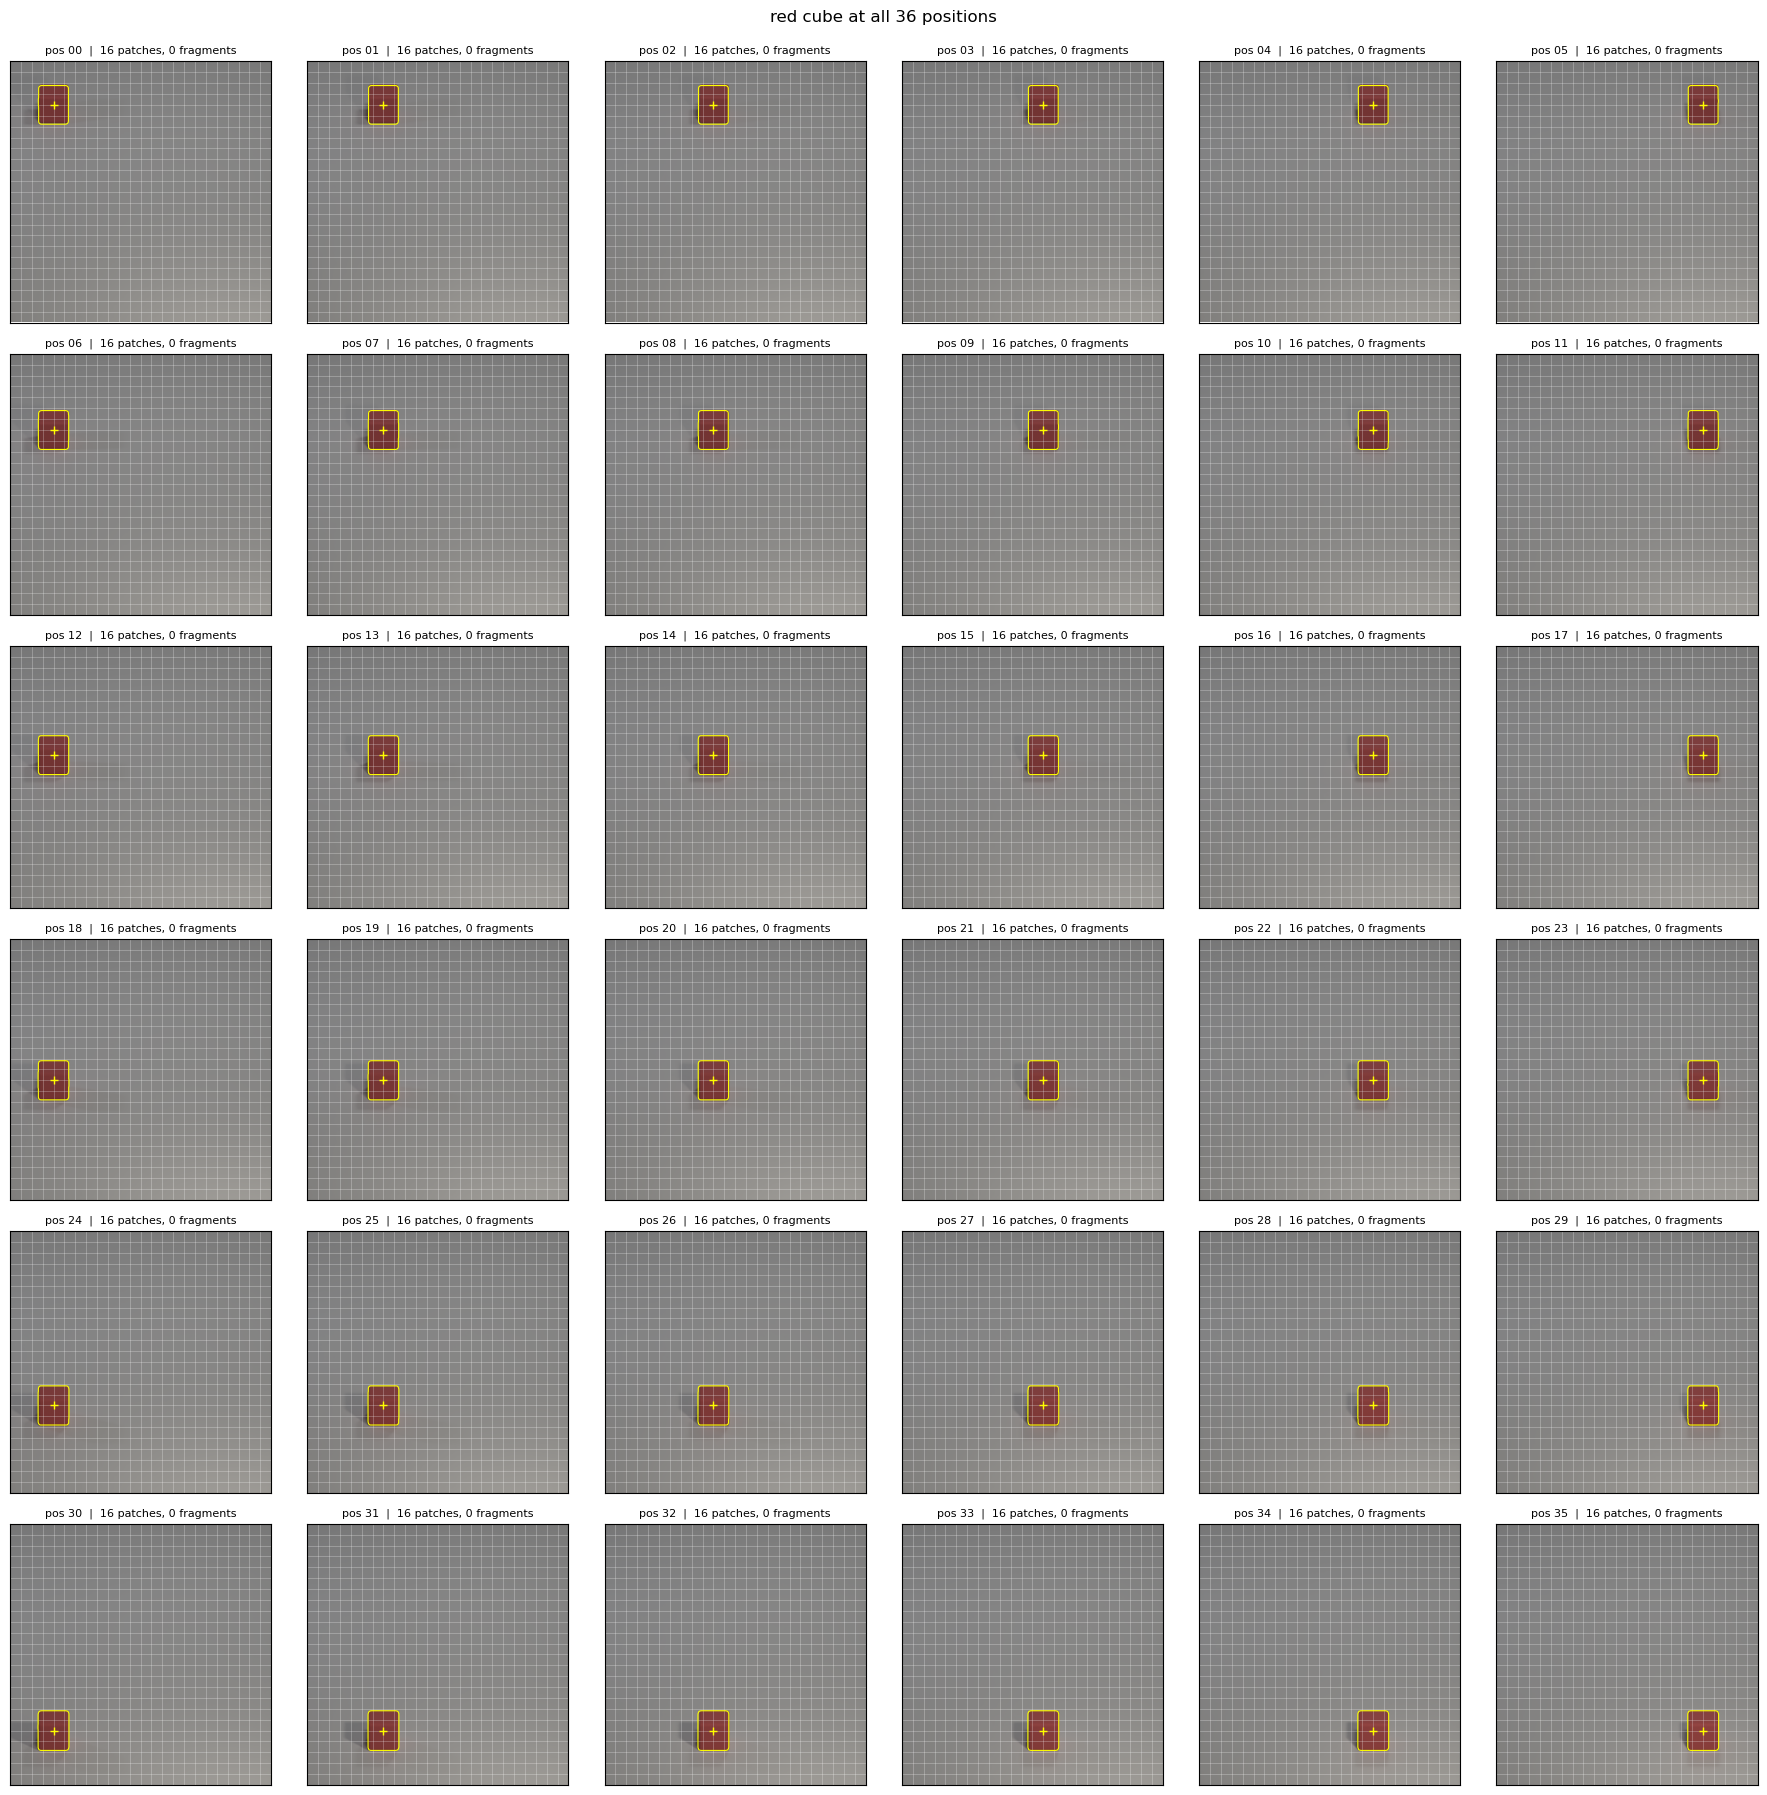

In [3]:
SHAPE = 'cube'     # sphere, cube, cylinder
COLOR = 'red'      # gray, red, blue, green, brown, purple, cyan, yellow

records = sorted([r for r in single_meta if r['shape'] == SHAPE and r['color'] == COLOR],
                 key=lambda r: r['position_index'])
fig, axes = plt.subplots(6, 6, figsize=(18, 18))
for r, ax in zip(records, axes.flat):
    pixel_cov, _ = single_mask(SHAPE, r['position_index'])
    show(ax, load_image(SINGLE / r['image']), [pixel_cov], [r['projected_center_px']],
         title=f"pos {r['position_index']:02d}  |  {r['patches_touched']} patches, "
               f"{r['patches_fragment']} fragments")
fig.suptitle(f'{COLOR} {SHAPE} at all 36 positions', y=0.995)
fig.tight_layout()

## 2. Zoom on one image: coverage of every patch

Left: the image with grid and outline. Right: the 24 × 24 patch-coverage map with the fraction of each touched patch. The coverage is measured on 4 × 4 supersampled masks, so it is exact to 1/16 of a pixel.

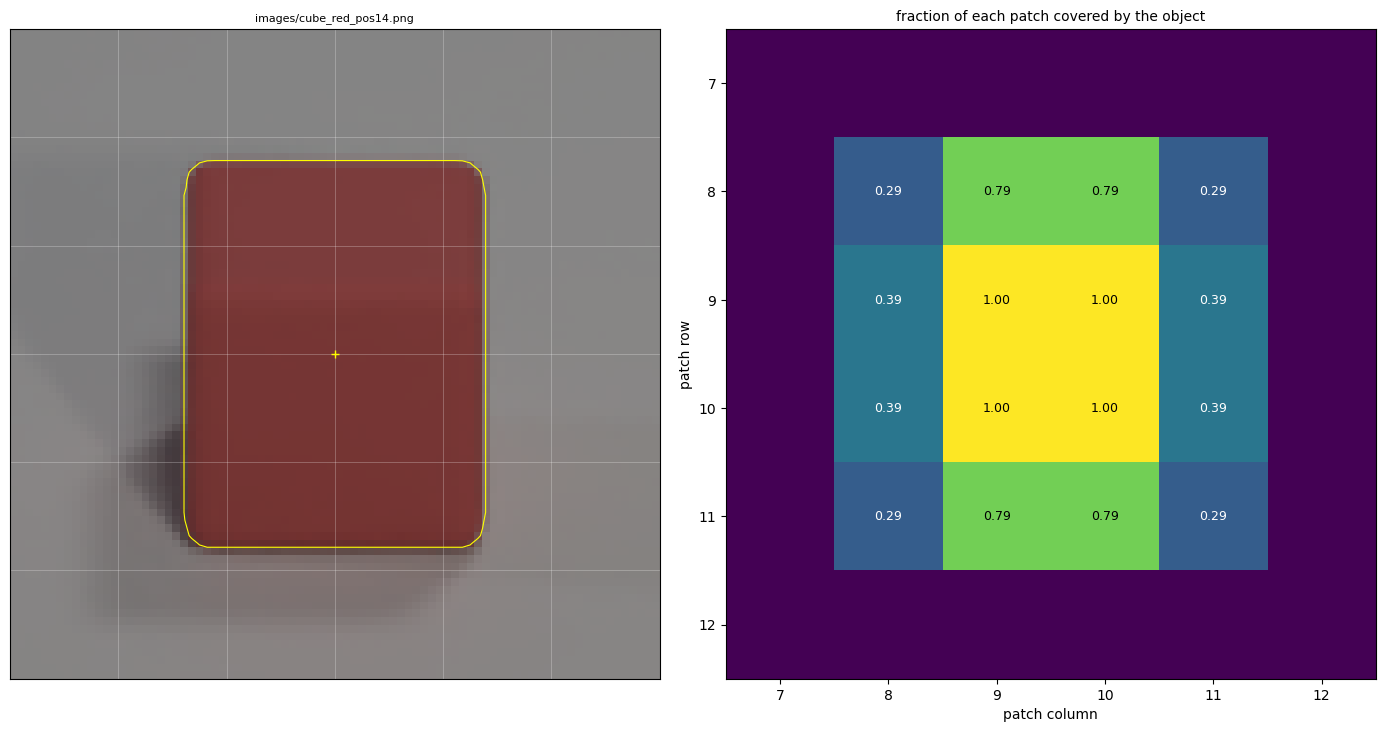

In [4]:
POSITION = 14

r = next(r for r in single_meta
         if r['shape'] == SHAPE and r['color'] == COLOR and r['position_index'] == POSITION)
pixel_cov, patch_cov = single_mask(SHAPE, POSITION)
row, col = np.nonzero(patch_cov)
r0, r1, c0, c1 = row.min() - 1, row.max() + 2, col.min() - 1, col.max() + 2

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 7))
show(ax1, load_image(SINGLE / r['image']), [pixel_cov], [r['projected_center_px']],
     title=f"{r['image']}")
ax1.set_xlim(c0 * PATCH - 0.5, c1 * PATCH - 0.5)
ax1.set_ylim(r1 * PATCH - 0.5, r0 * PATCH - 0.5)

ax2.imshow(patch_cov, cmap='viridis', vmin=0, vmax=1)
for i, j in zip(row, col):
    ax2.text(j, i, f'{patch_cov[i, j]:.2f}', ha='center', va='center', fontsize=9,
             color='black' if patch_cov[i, j] > 0.5 else 'white')
ax2.set_xlim(c0 - 0.5, c1 - 0.5)
ax2.set_ylim(r1 - 0.5, r0 - 0.5)
ax2.set_xticks(range(c0, c1))
ax2.set_yticks(range(r0, r1))
ax2.set_xlabel('patch column')
ax2.set_ylabel('patch row')
ax2.set_title('fraction of each patch covered by the object', fontsize=10)
fig.tight_layout()

## 3. All 36 positions of each shape in one picture

All masks of a shape drawn on the full patch grid. The projected centers sit exactly on patch corners, 3 patches (42 px) apart, so every object has the same position relative to the patch boundaries.

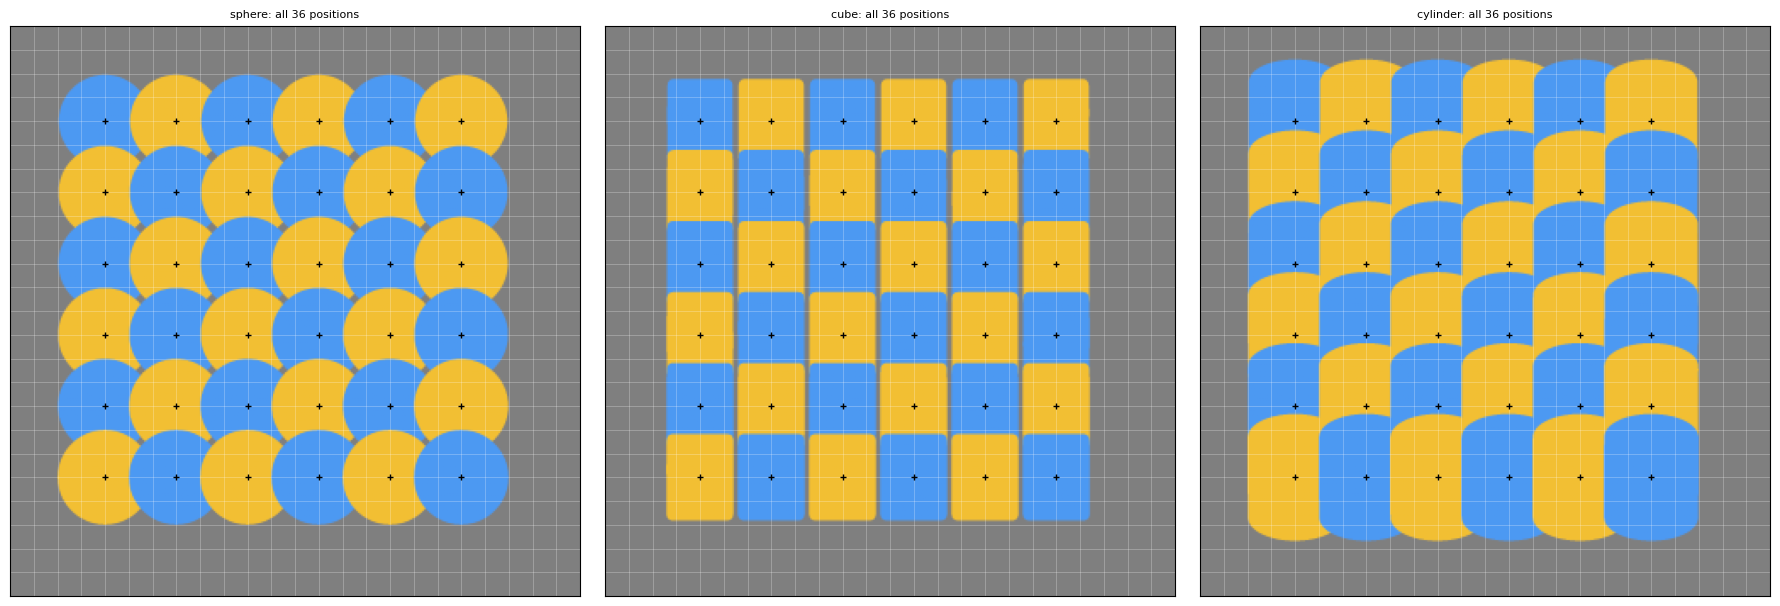

In [5]:
SHAPES = ['sphere', 'cube', 'cylinder']
centers = {r['position_index']: r['projected_center_px'] for r in single_meta}

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for shape, ax in zip(SHAPES, axes):
    canvas = np.full((IMAGE_SIZE, IMAGE_SIZE, 3), 0.5)
    for position in range(36):
        pixel_cov, _ = single_mask(shape, position)
        # Alternate colors in a checkerboard so neighboring masks are distinguishable
        color = np.array([0.95, 0.75, 0.2]) if (position // 6 + position % 6) % 2 else np.array([0.3, 0.6, 0.95])
        canvas = canvas * (1 - pixel_cov[..., None]) + color * pixel_cov[..., None]
    show(ax, canvas, title=f'{shape}: all 36 positions')
    for x, y in centers.values():
        ax.plot(x - 0.5, y - 0.5, '+', color='black', ms=5)
fig.tight_layout()

## 4. How much of each touched patch is covered

Distribution of the coverage of all patches that an object touches, over all 36 positions. The calibration aimed to avoid patches that hold only a tiny fragment (left of the dashed line, below 10%).

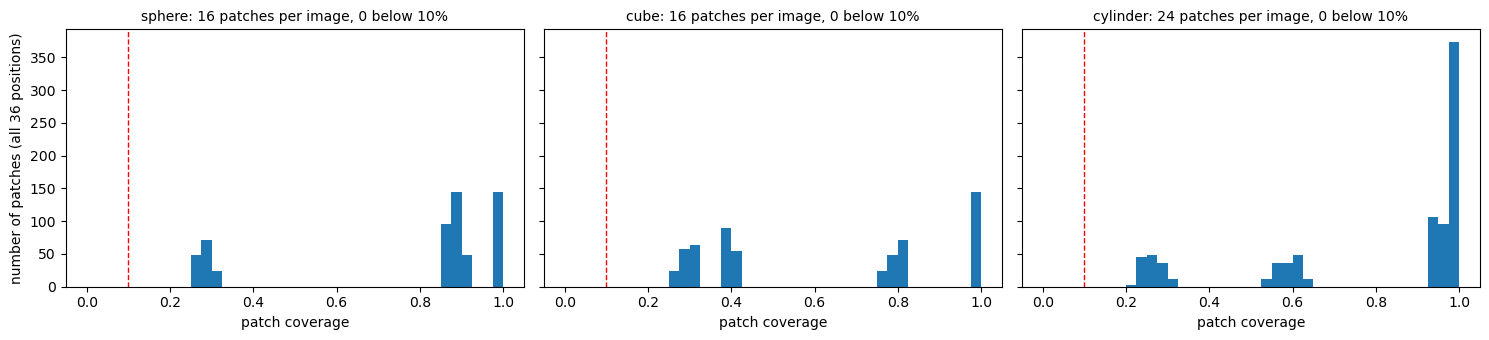

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5), sharey=True)
for shape, ax in zip(SHAPES, axes):
    values = np.concatenate([single_mask(shape, p)[1].ravel() for p in range(36)])
    values = values[values > 0]
    ax.hist(values, bins=np.linspace(0, 1, 41), color='tab:blue')
    ax.axvline(0.1, color='red', ls='--', lw=1)
    ax.set_title(f'{shape}: {len(values) // 36} patches per image, '
                 f'{(values < 0.1).sum()} below 10%', fontsize=10)
    ax.set_xlabel('patch coverage')
axes[0].set_ylabel('number of patches (all 36 positions)')
fig.tight_layout()

## 5. Two objects: the nine positions

The two-object dataset uses a 3 × 3 subset of the single-object grid (every other row and column), so neighboring positions are 6 patches (84 px) apart. Below: all three shapes at all nine positions, and the position IDs.

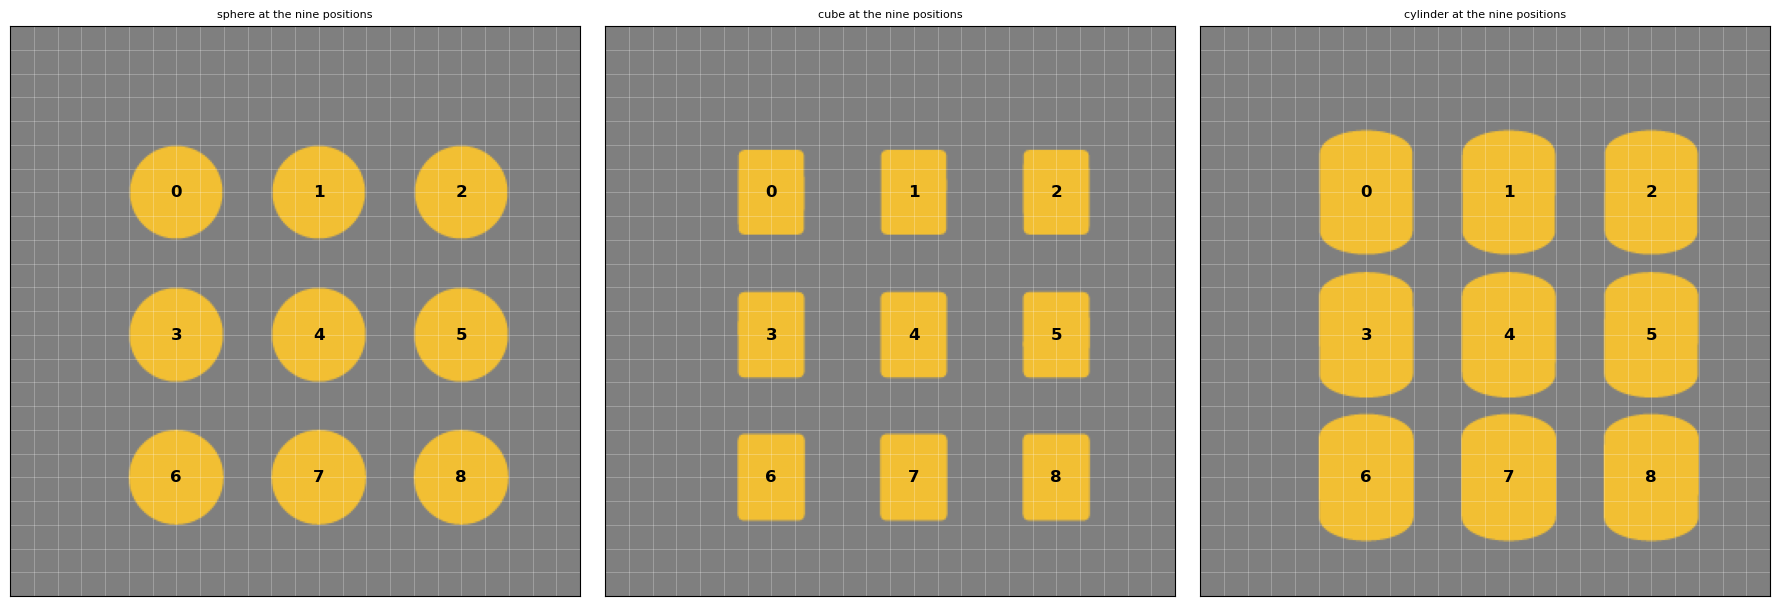

In [7]:
layout = json.loads((DUAL / 'layout.json').read_text())
dual_centers = {p['position_id']: p['target_px'] for p in layout['positions']}

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for shape, ax in zip(SHAPES, axes):
    canvas = np.full((IMAGE_SIZE, IMAGE_SIZE, 3), 0.5)
    for position in range(9):
        pixel_cov, _ = dual_mask(shape, position)
        canvas = canvas * (1 - pixel_cov[..., None]) + np.array([0.95, 0.75, 0.2]) * pixel_cov[..., None]
    show(ax, canvas, title=f'{shape} at the nine positions')
    for position, (x, y) in dual_centers.items():
        ax.text(x - 0.5, y - 0.5, str(position), ha='center', va='center', fontsize=12,
                color='black', weight='bold')
fig.tight_layout()

## 6. Two objects: one object fixed, the other at all remaining positions

`FIXED` is kept in place while the other object takes each of the other eight positions. Yellow outline: object in slot 0, magenta: slot 1 (slots are ordered by position ID). The title gives the gap between the two silhouettes and the number of patches touched by both objects (always 0).

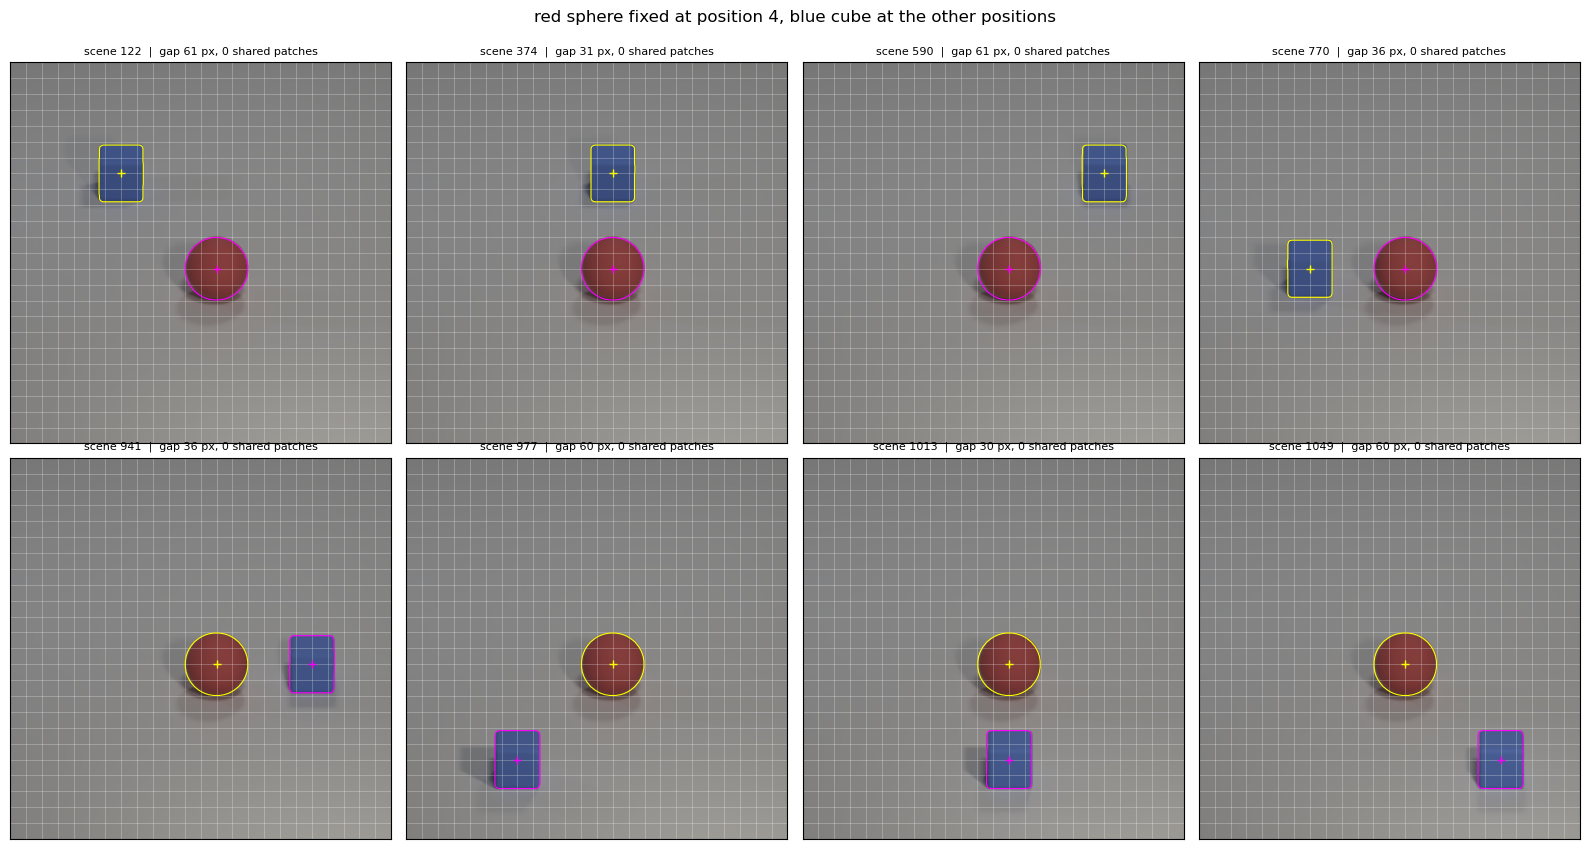

In [8]:
FIXED = (4, 'sphere', 'red')   # (position_id, shape, color)
OTHER = ('cube', 'blue')       # shape and color of the moving object

def matches(scene):
    objs = [(o['position_id'], o['shape'], o['color']) for o in scene['objects']]
    return FIXED in objs and any(o[1:] == OTHER and o[0] != FIXED[0] for o in objs)

chosen = sorted((s for s in dual_scenes if matches(s)),
                key=lambda s: [o['position_id'] for o in s['objects'] if o['position_id'] != FIXED[0]][0])
fig, axes = plt.subplots(2, 4, figsize=(16, 8.5))
for s, ax in zip(chosen, axes.flat):
    masks = [dual_mask(o['shape'], o['position_id'])[0] for o in s['objects']]
    show(ax, load_image(DUAL / s['image']), masks,
         [o['projected_center_px'] for o in s['objects']],
         title=f"scene {s['scene_id']}  |  gap {s['silhouette_gap_px']:.0f} px, "
               f"{s['shared_patches']} shared patches")
fig.suptitle(f'{FIXED[2]} {FIXED[1]} fixed at position {FIXED[0]}, '
             f'{OTHER[1]} {OTHER[0]} at the other positions', y=1.0)
fig.tight_layout()

## 7. Two objects: patch coverage of both objects in one scene

The tightest layout: two cylinders stacked in the same column (gap 10 px). The coverage map shows each object's patches; no patch contains both.

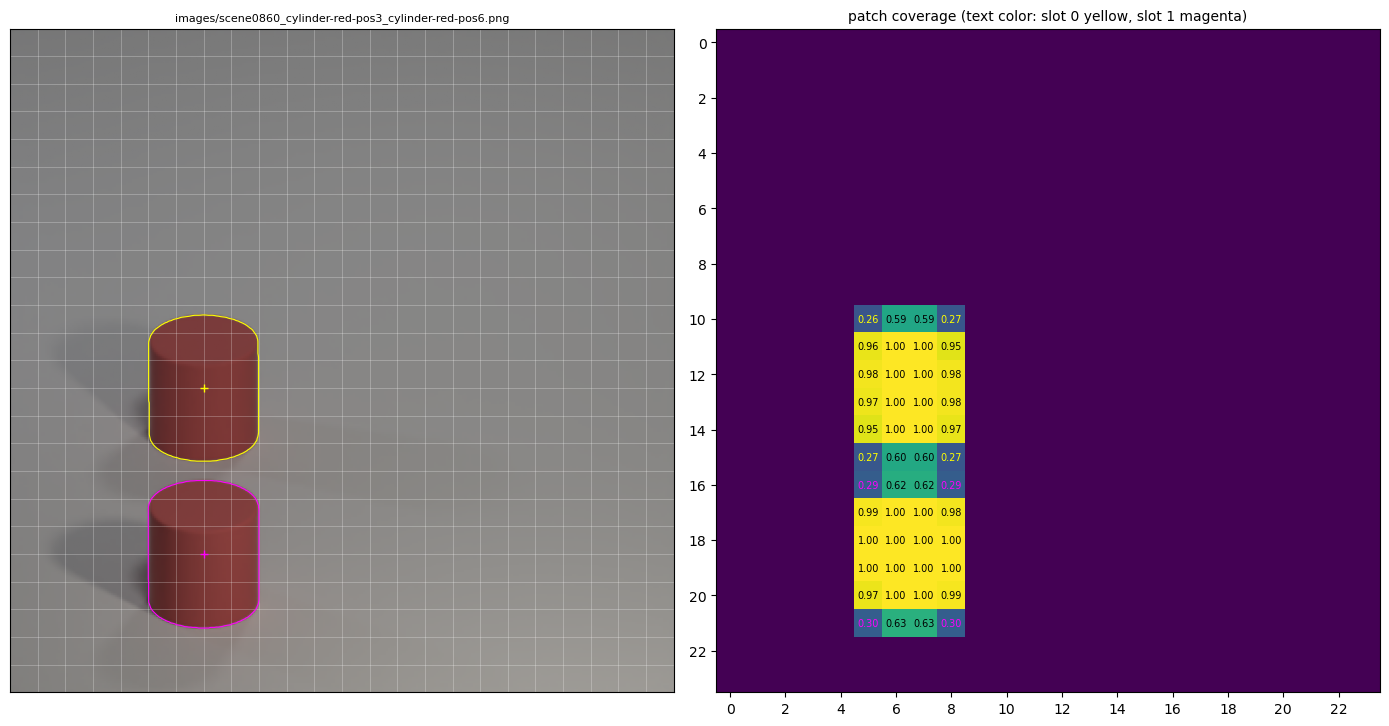

In [9]:
scene = min((s for s in dual_scenes
             if all(o['shape'] == 'cylinder' for o in s['objects'])),
            key=lambda s: s['silhouette_gap_px'])
masks, patch_maps = zip(*[dual_mask(o['shape'], o['position_id']) for o in scene['objects']])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 7))
show(ax1, load_image(DUAL / scene['image']), masks,
     [o['projected_center_px'] for o in scene['objects']], title=scene['image'])

combined = patch_maps[0] + patch_maps[1]
ax2.imshow(combined, cmap='viridis', vmin=0, vmax=1)
for k, pm in enumerate(patch_maps):
    for i, j in zip(*np.nonzero(pm)):
        ax2.text(j, i, f'{pm[i, j]:.2f}', ha='center', va='center', fontsize=7,
                 color=OUTLINE_COLORS[k] if pm[i, j] < 0.5 else 'black')
ax2.set_title('patch coverage (text color: slot 0 yellow, slot 1 magenta)', fontsize=10)
ax2.set_xticks(range(0, N_PATCHES, 2))
ax2.set_yticks(range(0, N_PATCHES, 2))
fig.tight_layout()